# Assignment 4 - One- and Two-Sample Tests

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas

Table of contents
1. Part 1 - One-sample decisions
2. Part 2 - Independent coating processes
3. Part 3 - Paired building-energy measurements
4. Part 4 - Comparing two independent proportions
5. Part 5 - AI-use and conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

In [2]:
sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")
coating = pd.read_csv("data/assignment04_coating_durability.csv")
energy = pd.read_csv("data/assignment04_energy_retrofit.csv")

display(sensors.head())
display(access.head())
display(coating.head())
display(energy.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


,specimen_id,process,durability_h
0,1,standard,112.45
1,2,standard,109.55
2,3,standard,131.35
3,4,standard,130.96
4,5,standard,110.15


,building_id,before_kwh_day,after_kwh_day
0,1,91.57,87.75
1,2,95.33,90.14
2,3,85.20,85.61
3,4,75.96,64.30
4,5,85.33,81.90


# Part 1 - One-sample decisions

## Mean sensor error

Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm{C}$ are regarded as small in practice.

**a.** State $H_0$, the two-sided $H_1$, and $\alpha = 0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

In [3]:
# TODO

*TODO: answer*

**b.** Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0 \mid \text{data})$.

*TODO: answer*

**c.** Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

In [4]:
# TODO

*TODO: answer*

## False-rejection probability

Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection probability exceeds the 5% target.

**a.** State the one-sided hypotheses. Perform an exact binomial test and report $\hat{p}$, the $p$-value, decision, and conclusion.

In [5]:
# TODO

*TODO: answer*

**b.** Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.

In [6]:
# TODO

*TODO: answer*

**c.** Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.

*TODO: answer*

# Part 2 - Independent coating processes

The file assignment04_coating_durability.csv contains independent specimens from a standard and modified coating process. Let

$$\delta = \mu_{\text{modified}} - \mu_{\text{standard}},$$

measured in durability hours. An increase of at least 8 hours is considered practically important.

Complete the following tasks:

**a.** Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

In [7]:
# TODO

*TODO: answer*

**b.** State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

In [8]:
# TODO

*TODO: answer*

**c.** Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

In [9]:
# TODO

*TODO: answer*

**d.** Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

*TODO: answer*

# Part 3 - Paired building-energy measurements

The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference

$$D = \text{before} - \text{after},$$

so a positive value represents a reduction.

Complete the following tasks:

**a.** Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.

In [10]:
energy["D"] = energy["before_kwh_day"] - energy["after_kwh_day"]
D = energy["D"]

n = len(D)
mean_D = D.mean()
sd_D = D.std()
se_D = sd_D / np.sqrt(n)

print(f"n = {n}")
print(f"mean of D = {mean_D:.2f} kWh/day")
print(f"SD of D   = {sd_D:.2f} kWh/day")
print(f"SE of D   = {se_D:.2f} kWh/day")

n = 36
mean of D = 4.82 kWh/day
SD of D   = 4.50 kWh/day
SE of D   = 0.75 kWh/day


The observational unit is one building. Each row is one building measured twice, once before and once after the retrofit.

The rows are genuine pairs because both values in a row come from the same building (same building_id). A building keeps its size and its type of use, so these do not change much between the two measurements. The pairing comes from how the study was set up, we did not match the values afterwards.

The mean difference is 4.82 kWh/day, the SD is 4.50 kWh/day and the SE is 4.50/√36 = 0.75 kWh/day. So on average the buildings used about 4.8 kWh/day less after the retrofit.

**b.** Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.

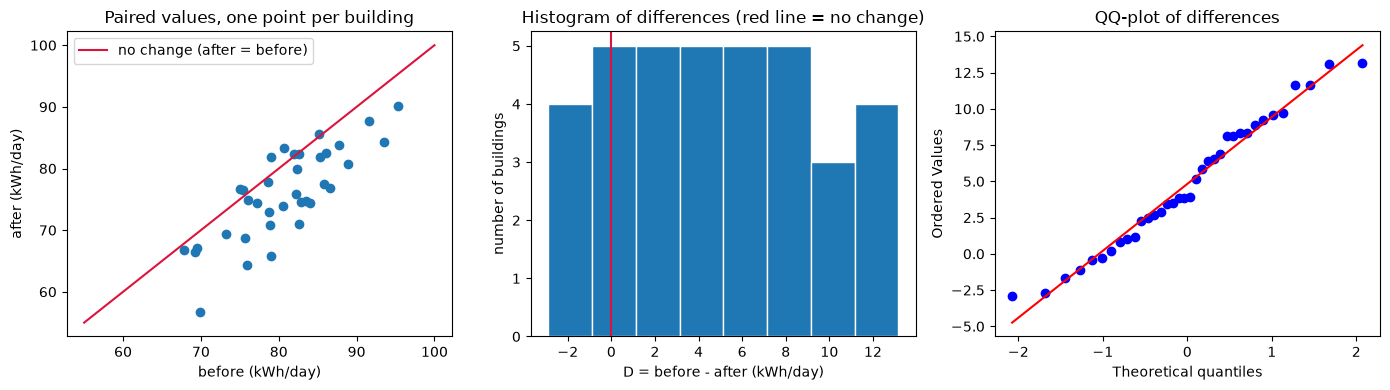

buildings with lower use after: 30 of 36
mean = 4.82, median = 3.90, min = -2.90, max = 13.17


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(energy["before_kwh_day"], energy["after_kwh_day"])
axes[0].plot([55, 100], [55, 100], color="crimson", label="no change (after = before)")
axes[0].set_title("Paired values, one point per building")
axes[0].set_xlabel("before (kWh/day)")
axes[0].set_ylabel("after (kWh/day)")
axes[0].legend()

axes[1].hist(D, bins=8, edgecolor="white")
axes[1].axvline(0, color="crimson")
axes[1].set_title("Histogram of differences (red line = no change)")
axes[1].set_xlabel("D = before - after (kWh/day)")
axes[1].set_ylabel("number of buildings")

stats.probplot(D, plot=axes[2])
axes[2].set_title("QQ-plot of differences")

plt.tight_layout()
plt.show()

print(f"buildings with lower use after: {(D > 0).sum()} of {n}")
print(f"mean = {mean_D:.2f}, median = {D.median():.2f}, min = {D.min():.2f}, max = {D.max():.2f}")

In the left plot most points are below the red line, which means lower energy use after the retrofit. 30 of the 36 buildings went down and 6 went up.

The paired t procedure only uses the differences, so we check those and not the two raw columns. The histogram is quite flat and not a clear bell shape, but it has no strong skew (mean 4.82, median 3.90) and only 36 points, so its shape is rough anyway. In the QQ-plot the points stay close to the line, with only small gaps at the two ends. There are no outliers. The building that looks far from the others in the left plot (building 20) has one of the largest differences (about 13 kWh/day), but this value still fits the line in the QQ-plot.

With no big problem in the shape and n = 36, the paired t procedure looks reasonable. The plots cannot show if the buildings are independent of each other. For example, buildings with the same owner or in the same area could be related, and we would need to know more about the study to check this.

**c.** Test $H_0: \mu_D = 0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.

In [12]:
paired = stats.ttest_rel(energy["before_kwh_day"], energy["after_kwh_day"])
paired_ci = paired.confidence_interval(0.95)

print(f"t = {paired.statistic:.2f}, df = {paired.df}, p-value = {paired.pvalue:.2g}")
print(f"95% CI for mean D = ({paired_ci.low:.2f}, {paired_ci.high:.2f}) kWh/day")

t = 6.43, df = 35, p-value = 2.1e-07
95% CI for mean D = (3.30, 6.35) kWh/day


H0: μD = 0 (no change in mean energy use). H1: μD ≠ 0. We use α = 0.05.

We get t = 6.43 with df = 35 and p ≈ 2.1e-07. If the true mean difference was 0 and the assumptions hold, a t value this far from 0 would almost never happen, so we reject H0. The data give strong evidence that mean energy use changed, and the change is a reduction.

The 95% CI for μD is (3.30, 6.35) kWh/day. It does not include 0, which matches the test result.

**d.** Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.

In [13]:
# Only to compare with the paired result, not a valid test for this data
indep = stats.ttest_ind(energy["before_kwh_day"], energy["after_kwh_day"], equal_var=False)
indep_ci = indep.confidence_interval(0.95)
se_indep = mean_D / indep.statistic

print(f"correlation of before and after = {energy['before_kwh_day'].corr(energy['after_kwh_day']):.2f}")
print(f"SE paired = {se_D:.2f}, SE independent = {se_indep:.2f}")
print(f"95% CI paired      = ({paired_ci.low:.2f}, {paired_ci.high:.2f}), width {paired_ci.high - paired_ci.low:.2f}")
print(f"95% CI independent = ({indep_ci.low:.2f}, {indep_ci.high:.2f}), width {indep_ci.high - indep_ci.low:.2f}")
print(f"mean before = {energy['before_kwh_day'].mean():.2f} kWh/day")
print(f"reduction in percent: {mean_D / energy['before_kwh_day'].mean():.1%}")

correlation of before and after = 0.80
SE paired = 0.75, SE independent = 1.65
95% CI paired      = (3.30, 6.35), width 3.05
95% CI independent = (1.53, 8.12), width 6.58
mean before = 80.78 kWh/day
reduction in percent: 6.0%


An independent-samples test would treat the before and after values as two separate groups of buildings. But they are the same buildings, and the two columns are strongly related (correlation 0.80), so that test's assumption is not true here. It would also count the normal differences between big and small energy users as noise. Pairing removes these differences because each building is compared with itself. This is why the SE is 0.75 for the paired test and 1.65 for the independent test, and the CI is much narrower (width 3.05 against 6.58 kWh/day).

We estimate that the retrofit is linked to a mean reduction of 4.82 kWh/day per building, and values from 3.30 to 6.35 kWh/day are plausible. That is about 6% of the mean use before the retrofit (roughly 4% to 8%). Over a year it is about 1,760 kWh per building (roughly 1,200 to 2,300 kWh).

Our recommendation is to continue with the retrofit if the cost is justified by savings at the low end of the interval, about 3.3 kWh/day. We do not have cost data, so the data alone cannot decide this. There is also no control group. Weather or building use could have changed between the two periods, so we cannot be sure that the retrofit caused the whole reduction. Also, 6 buildings went up, so it would be good to check those before a wider rollout.

# Part 4 - Comparing two independent proportions

Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A - p_B$.

Complete the following tasks:

**a.** State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.

*TODO: answer*

**b.** Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.

In [14]:
# TODO

*TODO: answer*

**c.** Test $H_0: p_A = p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

In [15]:
# TODO

*TODO: answer*

**d.** State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

*TODO: answer*

# Part 5 - AI-use and conclusion

## AI-use

State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the final work. A short paragraph or table is sufficient.

*TODO: answer*

## Overall conclusion

Write approximately 150–250 words comparing what the four designs allow you to conclude. Include effects and intervals, not only decisions, and distinguish statistical significance, practical importance, and causal interpretation.

Only use Sessions 7–8. Do not use ANOVA, regression, or chi-square methods.

*TODO: answer*